In [1]:
import scanpy as sc
import squidpy as sq

/opt/conda/envs/ctSVG/lib/python3.12/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/opt/conda/envs/ctSVG/lib/python3.12/site-packages/anndata/__init__.py:44: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  return module_get_attr_redirect(attr_name, deprecated_mapping=_DEPRECATED)


## Human Kidney Cancer

## Representation Learning
```bash
python RepresentationLearning.py --project "Human Kidney Cancer Interface" \
--data.filename "spatialscope_output/Human Kidney Cancer Interface/sp_adata.h5ad" \
--data.preprocess \
--model.n_in 2215 --model.n_out 200 \
--trainer.accelerator gpu --trainer.strategy ddp --trainer.num_nodes 1 --trainer.devices 4 \
--trainer.num_epochs 1000 --trainer.batch_size 512
```

## Clustering
```bash
python Clustering.py --project "Human Kidney Cancer Interface" \
--resolution 0.01
```

In [31]:
adata_clusters_filename = "gctsvg_output/Human Kidney Cancer Interface/clustering/adata_clusters.h5ad"
adata_clusters = sc.read(adata_clusters_filename)

In [32]:
adata_clusters

AnnData object with n_obs × n_vars = 2047 × 2215
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'mt_frac', 'donor_id', 'region', 'n_counts', 'cell_count', 'leiden'
    var: 'feature_types', 'genome', 'SYMBOL', 'mt', 'n_cells_by_counts-6800STDY12499411', 'mean_counts-6800STDY12499411', 'log1p_mean_counts-6800STDY12499411', 'pct_dropout_by_counts-6800STDY12499411', 'total_counts-6800STDY12499411', 'log1p_total_counts-6800STDY12499411', 'estimated_be'
    uns: 'cell_locations', 'leiden', 'log1p', 'neighbors', 'sample_colors', 'spatial'
    obsm: 'embedding', 'image_features', 'spatial'
    layers: 'original', 'reconstruction'
    obsp: 'connectivities', 'distances'

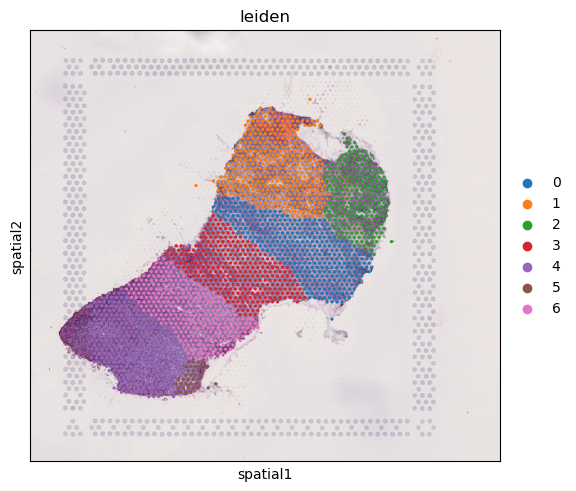

In [33]:
sq.pl.spatial_scatter(adata_clusters, color="leiden")